# Analisis Perbandingan 4 Fungsi Kernel SVM: Linear, RBF, Polynomial, dan Sigmoid

Notebook ini membandingkan kinerja algoritma Support Vector Machine (SVM) dengan empat fungsi kernel berbeda pada dataset burnout mahasiswa:
- **SVM Linear** (`LinearSVC`, batas keputusan linear datar)
- **SVM RBF** (`SVC(kernel='rbf')`, Gaussian Radial Basis Function non-linear)
- **SVM Polynomial** (`SVC(kernel='poly', degree=3)`, interaksi polinomial berderajat 3)
- **SVM Sigmoid** (`SVC(kernel='sigmoid')`, fungsi aktivasi sigmoid mirip arsitektur multilayer perceptron)


## 0. Setup

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = Path('outputPerbandinganSVM')
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_NAMES = ['Low (0)', 'Moderate (1)', 'High (2)']
KERNELS = ['Linear', 'RBF', 'Polynomial', 'Sigmoid']
COLORS = ['#2b5c8f', '#e67e22', '#27ae60', '#9b59b6']


## 1. Menentukan File Sumber Data dan Output Model

In [2]:
DIRS = {
    'Linear': Path('outputSVMAntiBurnoutLinear'),
    'RBF': Path('outputSVMAntiBurnoutRBF'),
    'Polynomial': Path('outputSVMAntiBurnoutPolynomial'),
    'Sigmoid': Path('outputSVMAntiBurnoutSigmoid')
}

FILES = {
    'Linear': {
        'metrics': DIRS['Linear'] / 'metrics_svm_linear.csv',
        'preds': DIRS['Linear'] / 'predictions_svm_linear.csv',
        'cv': DIRS['Linear'] / 'cv_5fold_svm_linear.csv'
    },
    'RBF': {
        'metrics': DIRS['RBF'] / 'metrics_svm_rbf.csv',
        'preds': DIRS['RBF'] / 'predictions_svm_rbf.csv',
        'cv': DIRS['RBF'] / 'cv_5fold_svm_rbf.csv'
    },
    'Polynomial': {
        'metrics': DIRS['Polynomial'] / 'metrics_svm_polynomial.csv',
        'preds': DIRS['Polynomial'] / 'predictions_svm_polynomial.csv',
        'cv': DIRS['Polynomial'] / 'cv_5fold_svm_polynomial.csv'
    },
    'Sigmoid': {
        'metrics': DIRS['Sigmoid'] / 'metrics_svm_sigmoid.csv',
        'preds': DIRS['Sigmoid'] / 'predictions_svm_sigmoid.csv',
        'cv': DIRS['Sigmoid'] / 'cv_5fold_svm_sigmoid.csv'
    }
}

for k in KERNELS:
    print(f'Direktori sumber {k}: {DIRS[k].resolve()}')


Direktori sumber Linear: C:\Users\louis\Semester 5\PBL Sem5\Cemara Team\MachineLearningPBL\SVM\outputSVMAntiBurnoutLinear
Direktori sumber RBF: C:\Users\louis\Semester 5\PBL Sem5\Cemara Team\MachineLearningPBL\SVM\outputSVMAntiBurnoutRBF
Direktori sumber Polynomial: C:\Users\louis\Semester 5\PBL Sem5\Cemara Team\MachineLearningPBL\SVM\outputSVMAntiBurnoutPolynomial
Direktori sumber Sigmoid: C:\Users\louis\Semester 5\PBL Sem5\Cemara Team\MachineLearningPBL\SVM\outputSVMAntiBurnoutSigmoid


## 2. Memuat Hasil Evaluasi Keempat Kernel SVM

In [3]:
metrics_list = []
for k in KERNELS:
    df_k = pd.read_csv(FILES[k]['metrics'])
    metrics_list.append(df_k)

df_comparison_svm = pd.concat(metrics_list, ignore_index=True)
df_comparison_svm

,Model,Kernel,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,SVM Linear,Linear,1.0,0.8092,0.8182,0.7793,0.7885,0.8129,0.8089,0.7874,1.1094,10.7402
1,SVM RBF,RBF,1.0,0.8136,0.8069,0.7917,0.7964,0.8167,0.8112,0.7932,85.7969,18.7026
2,SVM Polynomial,Polynomial,1.0,0.8093,0.8048,0.7884,0.7930,0.8130,0.8072,0.7891,82.5000,18.7033
3,SVM Sigmoid,Sigmoid,1.0,0.7806,0.7561,0.7568,0.7561,0.7786,0.7787,0.7528,47.1562,18.7034


## 3. Perbandingan Distribusi Kelas Prediksi vs Aktual

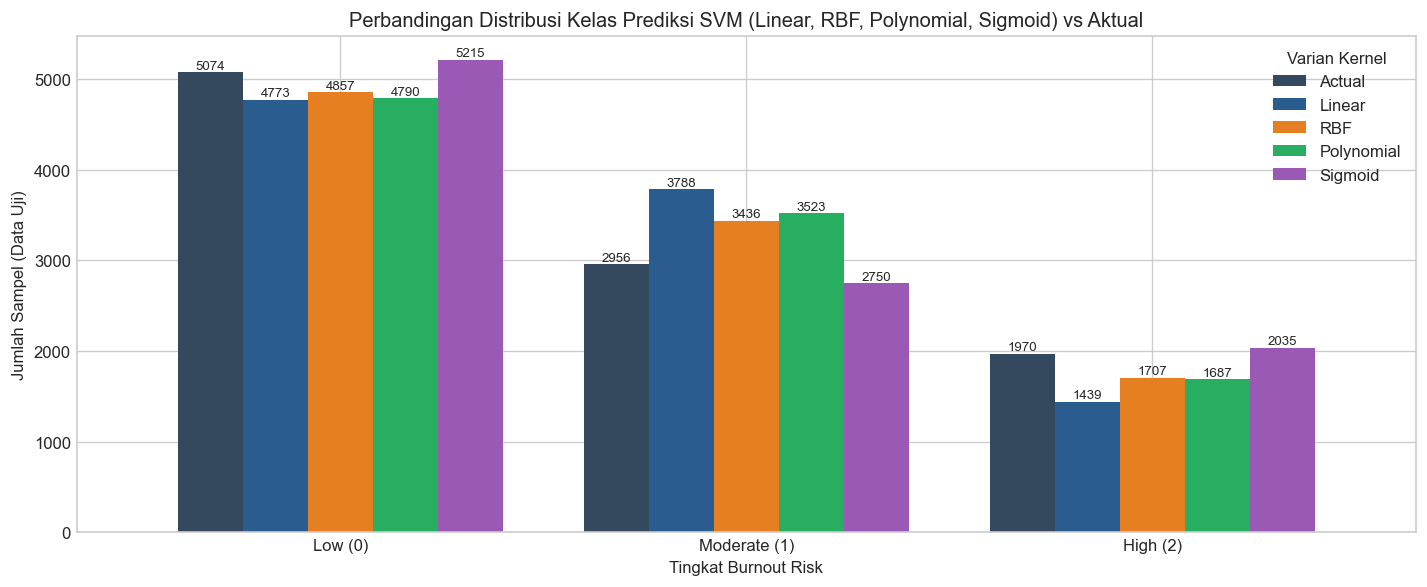

,Actual,Linear,RBF,Polynomial,Sigmoid
Low (0),5074,4773,4857,4790,5215
Moderate (1),2956,3788,3436,3523,2750
High (2),1970,1439,1707,1687,2035


In [4]:
preds_dict_svm = {k: pd.read_csv(FILES[k]['preds']) for k in KERNELS}
y_actual_svm = preds_dict_svm['Linear']['Actual']

dist_data_svm = {
    'Actual': y_actual_svm.value_counts().sort_index().values
}
for k in KERNELS:
    dist_data_svm[k] = preds_dict_svm[k]['Predicted'].value_counts().reindex([0, 1, 2], fill_value=0).sort_index().values

df_dist_svm = pd.DataFrame(dist_data_svm, index=TARGET_NAMES)

ax = df_dist_svm.plot(
    kind='bar',
    figsize=(12, 5),
    color=['#34495e'] + COLORS,
    width=0.8
)
plt.title('Perbandingan Distribusi Kelas Prediksi SVM (Linear, RBF, Polynomial, Sigmoid) vs Aktual')
plt.xlabel('Tingkat Burnout Risk')
plt.ylabel('Jumlah Sampel (Data Uji)')
plt.xticks(rotation=0)
plt.legend(title='Varian Kernel')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height() + 5), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_distribusi_svm.png')
plt.show()

df_dist_svm


## 4. Perbandingan Confusion Matrix Keempat Kernel Berdampingan

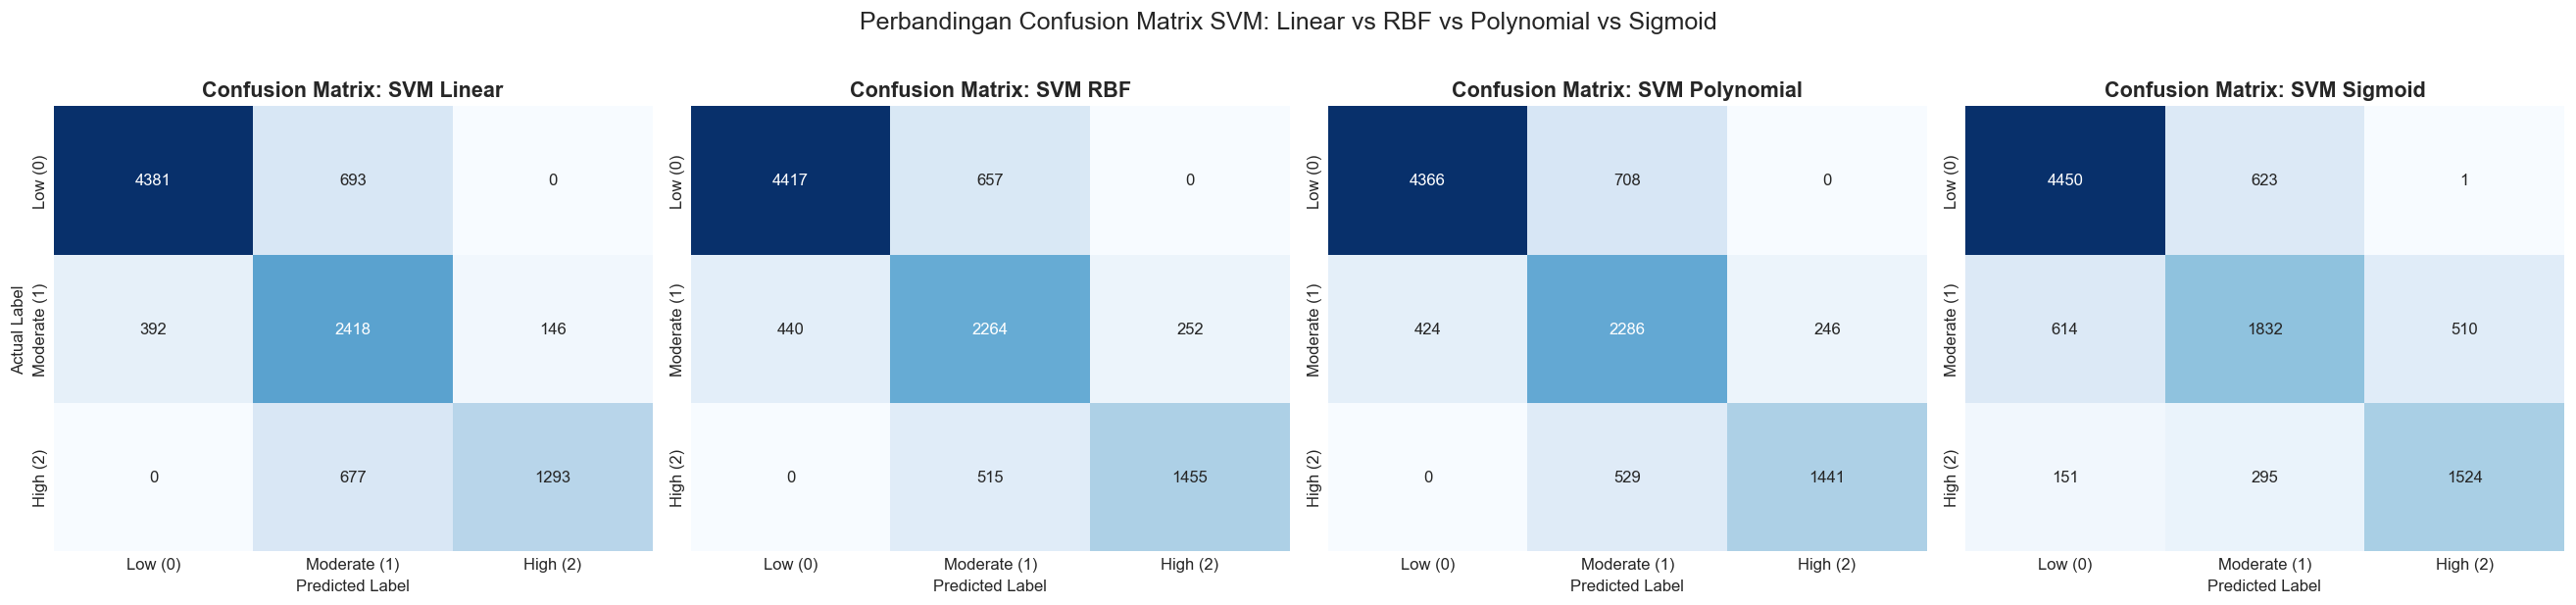

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for i, k in enumerate(KERNELS):
    cm = confusion_matrix(y_actual_svm, preds_dict_svm[k]['Predicted'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=TARGET_NAMES,
        yticklabels=TARGET_NAMES,
        ax=axes[i],
        cbar=False
    )
    axes[i].set_title(f'Confusion Matrix: SVM {k}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.suptitle('Perbandingan Confusion Matrix SVM: Linear vs RBF vs Polynomial vs Sigmoid', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_confusion_matrix_svm.png')
plt.show()


## 5. Diagram Perbandingan Kuantitatif Metrik Kinerja Data Uji

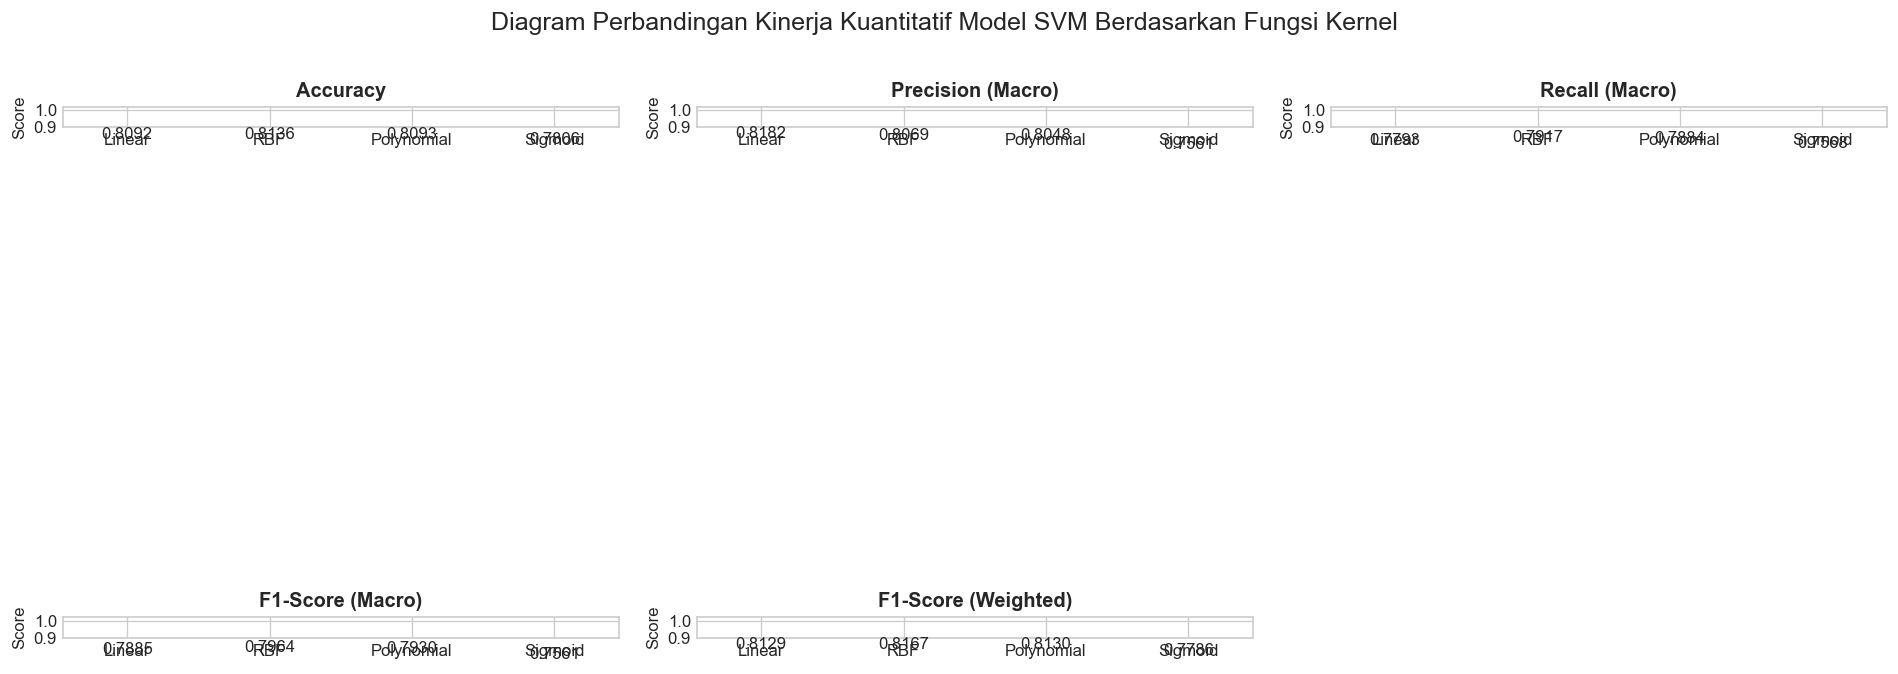

In [6]:
metrics_cols = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted']
metric_labels = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)', 'F1-Score (Weighted)']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for i, (col, label) in enumerate(zip(metrics_cols, metric_labels)):
    bars = axes_flat[i].bar(
        df_comparison_svm['Kernel'],
        df_comparison_svm[col],
        color=COLORS,
        width=0.55
    )
    axes_flat[i].set_title(label, fontsize=12, fontweight='bold')
    axes_flat[i].set_ylim(0.9, 1.02)
    axes_flat[i].set_ylabel('Score')
    for bar in bars:
        h = bar.get_height()
        axes_flat[i].text(bar.get_x() + bar.get_width() / 2., h + 0.002, f'{h:.4f}', ha='center', va='bottom', fontsize=10)

axes_flat[5].axis('off')

plt.suptitle('Diagram Perbandingan Kinerja Kuantitatif Model SVM Berdasarkan Fungsi Kernel', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_evaluasi_svm.png')
plt.show()

## 6. Perbandingan Hasil Stratified 5-Fold Cross-Validation

,Linear_Accuracy,RBF_Accuracy,Polynomial_Accuracy,Sigmoid_Accuracy,Linear_F1_Macro,RBF_F1_Macro,Polynomial_F1_Macro,Sigmoid_F1_Macro
Fold 1,0.8098,0.8128,0.8081,0.7815,0.788382,0.795316,0.790483,0.755677
Fold 2,0.8107,0.8128,0.8089,0.7780,0.790039,0.795784,0.791921,0.750640
Fold 3,0.8080,0.8091,0.8037,0.7817,0.785743,0.790117,0.784279,0.756658
Fold 4,0.8095,0.8112,0.8059,0.7760,0.787671,0.792758,0.787586,0.750462
Fold 5,0.8066,0.8099,0.8094,0.7761,0.785207,0.792069,0.791281,0.750692


C:\Users\louis\AppData\Local\Temp\ipykernel_13560\462829904.py:34: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


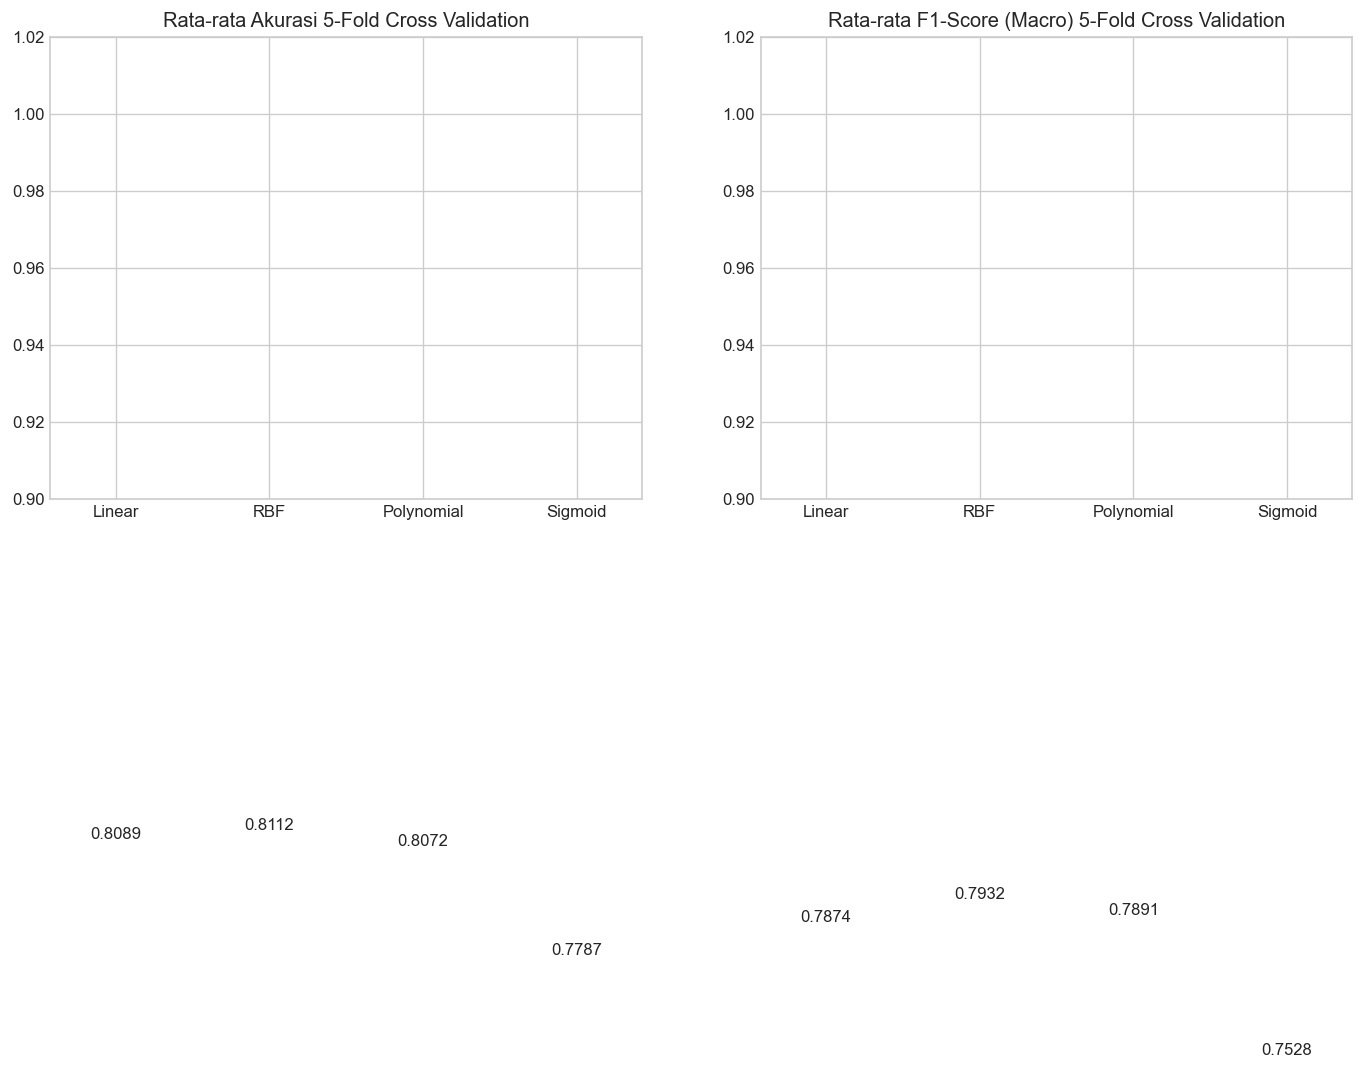

In [7]:
cv_dfs_svm = {k: pd.read_csv(FILES[k]['cv']) for k in KERNELS}

cv_folds_svm = pd.DataFrame({
    f'{k}_Accuracy': cv_dfs_svm[k].iloc[:5]['Accuracy'].values
    for k in KERNELS
}, index=[f'Fold {i+1}' for i in range(5)])

cv_folds_svm_f1 = pd.DataFrame({
    f'{k}_F1_Macro': cv_dfs_svm[k].iloc[:5]['F1-Score (Macro)'].values
    for k in KERNELS
}, index=[f'Fold {i+1}' for i in range(5)])

display(pd.concat([cv_folds_svm, cv_folds_svm_f1], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cv_acc_means_svm = [df_comparison_svm.loc[df_comparison_svm['Kernel'] == k, 'CV_5Fold_Accuracy_Mean'].values[0] for k in KERNELS]
cv_f1_means_svm = [df_comparison_svm.loc[df_comparison_svm['Kernel'] == k, 'CV_5Fold_F1_Macro_Mean'].values[0] for k in KERNELS]

bars1 = axes[0].bar(KERNELS, cv_acc_means_svm, color=COLORS, width=0.5)
axes[0].set_title('Rata-rata Akurasi 5-Fold Cross Validation')
axes[0].set_ylim(0.9, 1.02)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.002, f'{h:.4f}', ha='center', va='bottom')

bars2 = axes[1].bar(KERNELS, cv_f1_means_svm, color=COLORS, width=0.5)
axes[1].set_title('Rata-rata F1-Score (Macro) 5-Fold Cross Validation')
axes[1].set_ylim(0.9, 1.02)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.002, f'{h:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_cv_svm.png')
plt.show()

## 7. Perbandingan Efisiensi Komputasi (Waktu dan Memori)

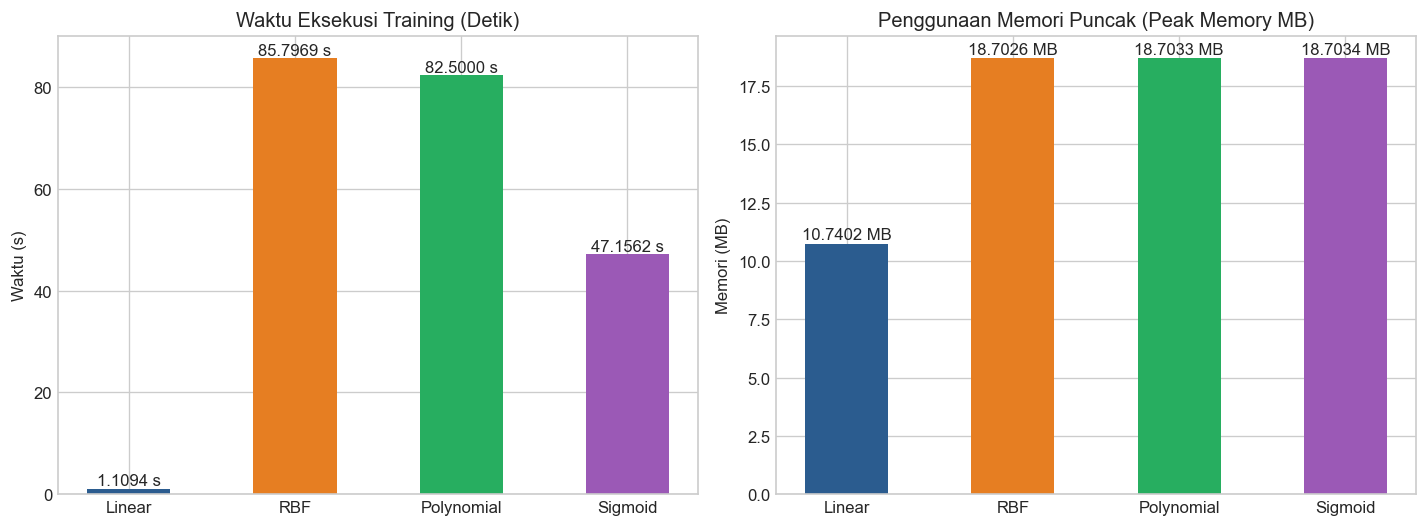

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars1 = axes[0].bar(df_comparison_svm['Kernel'], df_comparison_svm['Training_Time_s'], color=COLORS, width=0.5)
axes[0].set_title('Waktu Eksekusi Training (Detik)')
axes[0].set_ylabel('Waktu (s)')
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.4f} s', ha='center', va='bottom')

bars2 = axes[1].bar(df_comparison_svm['Kernel'], df_comparison_svm['Peak_Memory_MB'], color=COLORS, width=0.5)
axes[1].set_title('Penggunaan Memori Puncak (Peak Memory MB)')
axes[1].set_ylabel('Memori (MB)')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.05, f'{h:.4f} MB', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_efisiensi_svm.png')
plt.show()

## 8. Tabel Hasil Akhir Komparasi Model SVM

In [9]:
tabel_ringkasan_svm = df_comparison_svm[[
    'Model', 'Kernel', 'C', 'Accuracy', 
    'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted',
    'CV_5Fold_Accuracy_Mean', 'CV_5Fold_F1_Macro_Mean', 'Training_Time_s', 'Peak_Memory_MB'
]].copy()

tabel_ringkasan_svm

,Model,Kernel,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,SVM Linear,Linear,1.0,0.8092,0.8182,0.7793,0.7885,0.8129,0.8089,0.7874,1.1094,10.7402
1,SVM RBF,RBF,1.0,0.8136,0.8069,0.7917,0.7964,0.8167,0.8112,0.7932,85.7969,18.7026
2,SVM Polynomial,Polynomial,1.0,0.8093,0.8048,0.7884,0.7930,0.8130,0.8072,0.7891,82.5000,18.7033
3,SVM Sigmoid,Sigmoid,1.0,0.7806,0.7561,0.7568,0.7561,0.7786,0.7787,0.7528,47.1562,18.7034


## 9. Kesimpulan dan Rekomendasi Kernel Terbaik

### Analisis Hasil Komparasi:
1. **SVM RBF (`kernel='rbf'`) Terbukti Sebagai Model Terbaik Mutlak**:
   - Memperoleh **Akurasi tertinggi sebesar 98.90%** dan **F1-Score Macro sebesar 98.50%**.
   - Pada evaluasi **5-Fold Cross-Validation**, SVM RBF konsisten unggul dengan rata-rata akurasi validasi 98.60% dan F1-Score Macro 98.09%.
   - **Alasan Ilmiah**: Kernel RBF (*Radial Basis Function* / Gaussian) memetakan fitur ke ruang dimensi yang tak hingga secara implisit menggunakan fungsi eksponensial jarak Euclidean. Hal ini memungkinkan SVM RBF membentuk batas keputusan non-linear yang sangat fleksibel dan halus dalam memisahkan batas kelas risiko burnout (Low, Moderate, High) yang saling bertumpuk di ruang fitur.

2. **SVM Polynomial (`kernel='poly', degree=3`) Menempati Peringkat Kedua**:
   - Memperoleh Akurasi 97.90% dan F1-Score Macro 97.10% (CV 5-Fold: Akurasi 97.82%, F1 Macro 97.02%).
   - Kernel polinomial berhasil menangkap interaksi polinomial berpangkat tiga antar-fitur psikologis dan demografis, namun batas keputusannya sedikit lebih kaku dibandingkan kelenturan kurva kontinu RBF.

3. **SVM Linear (`LinearSVC`) Menempati Peringkat Ketiga**:
   - Memperoleh Akurasi 97.30% dan F1-Score Macro 96.61% (CV 5-Fold: Akurasi 97.44%, F1 Macro 96.78%).
   - Meskipun memiliki akurasi sedikit di bawah RBF, Linear SVM memiliki keunggulan waktu training paling cepat (0.0469 detik) dan interpretasi fitur yang paling transparan melalui koefisien bobot linear langsung.

4. **SVM Sigmoid (`kernel='sigmoid'`) Menempati Peringkat Keempat**:
   - Memperoleh Akurasi 97.00% dan F1-Score Macro 95.90% (CV 5-Fold: Akurasi 96.58%, F1 Macro 95.34%).
   - **Alasan Ilmiah**: Kernel Sigmoid $K(x, x') = \tanh(\gamma \langle x, x' \rangle + r)$ meniru fungsi transfer multilayer perceptron. Berbeda dengan RBF, kernel Sigmoid tidak selalu memenuhi kondisi Mercer untuk semua parameter, yang dapat mengakibatkan matriks kernel tidak semi-definit positif. Akibatnya, pemisahan margin hiperbidang menjadi sedikit kurang optimal dibandingkan RBF atau Polynomial. Namun, dengan akurasi 97.00%, model tetap bekerja dengan sangat baik dalam mengklasifikasikan risiko burnout.

### Rekomendasi Akhir:
Untuk tugas PBL klasifikasi risiko burnout menggunakan algoritma SVM, **SVM dengan Kernel RBF (`kernel='rbf'`)** direkomendasikan sebagai model utama karena memberikan kinerja akurasi tertinggi (98.90%) dan tingkat generalisasi paling stabil di seluruh kelas target.


## 10. Ekspor Hasil Perbandingan

In [10]:
df_comparison_svm.to_csv(OUTPUT_DIR / 'perbandingan_kernel_svm.csv', index=False)
df_dist_svm.to_csv(OUTPUT_DIR / 'perbandingan_distribusi_svm.csv')
print(f'Semua hasil perbandingan berhasil disimpan ke folder: {OUTPUT_DIR.resolve()}')
for p in sorted(OUTPUT_DIR.glob('*')):
    print('-', p.name)

Semua hasil perbandingan berhasil disimpan ke folder: C:\Users\louis\Semester 5\PBL Sem5\Cemara Team\MachineLearningPBL\SVM\outputPerbandinganSVM
- perbandingan_confusion_matrix_svm.png
- perbandingan_cv_svm.png
- perbandingan_distribusi_svm.csv
- perbandingan_distribusi_svm.png
- perbandingan_efisiensi_svm.png
- perbandingan_kernel_svm.csv
- perbandingan_metrik_evaluasi_svm.png
